# Лабораторная работа 1_2_5

In [3]:
import pandas as pd 
import numpy as np

## Измерение момента угловой скорости при прецессии гироскопа

In [ ]:
# 1 )данные эксперимента

# ! Записать длину плеча рычага l
l = 120 # мм

data = {
    'mass': [218.7, 218.7, 218.7, 218.7, 141.7, 141.7, 141.7, 340.3, 340.3, 340.3, 91.5, 91.5, 116.1, 116.1],     # Масса груза
    'revolutions_N': [3, 2, 4, 4, 3, 3, 3, 3, 3, 3, 3, 3, 2.5, 3],    # Целое число оборотов
    'time_t': [2*60+14, 60+30, 180+1, 120+59, 180+29, 180+29, 180+29, 60+27, 60+28, 60+27, 5*60+25, 5*60+24, 180+34, 60*4+15], 
      # Время прецессии, сек
     # Скорость опускания рычага
}

# Опускание 
r_hyro = 12.5 # см, радиус гироскопа до точки прикладывания груза
# 1) 
drop = {
    'mass':[320.3, 320.3, 116,1, 116.1],
    'revolutions':[3,3,2.5,3],
    'drop': [15-12.5, 15-13, 17-11, 16-11.5]
}
m = 320.3
drop_1 = 15-12.5 # опускание в см


In [ ]:
# частота по фигруе лиссажу 400 Гц

In [14]:
df = pd.DataFrame(data)



ValueError: All arrays must be of the same length

In [ ]:
df = pd.DataFrame(data)

# 2) Расчет угловой скорости
df_new = pd.DataFrame({'mass':[], 't_mean':[]})
tmp = []
for idx, i in enumerate(df['time_t']):
    if df['mass'][idx] == df['mass'][idx+1]:
        tmp.append(i)
    else:
        df_new['t_mean'] = np.mean(tmp)
        df_new['mass'] = df['mass'][idx-1]

df['Omega'] = (2 * np.pi * df['revolutions_N']) / df['time_t']
df['M'] = (120*df['mass'])

# 3) Усреднение результатов по каждому значению момента M
# Группируем по 'M_torque' и считаем среднее для остальных колонок
'''
df_averaged = df.groupby('M_torque').agg(
    Omega_mean=('Omega', 'mean'),
    drop_speed_mean=('drop_speed', 'mean'),
    time_mean=('time_t', 'mean')
).reset_index()

print("Сырые данные всех замеров:")
print(df.head(10))
print("\nУсредненные данные для построения графика (Омега от M):")
print(df_averaged)
'''

KeyError: 178

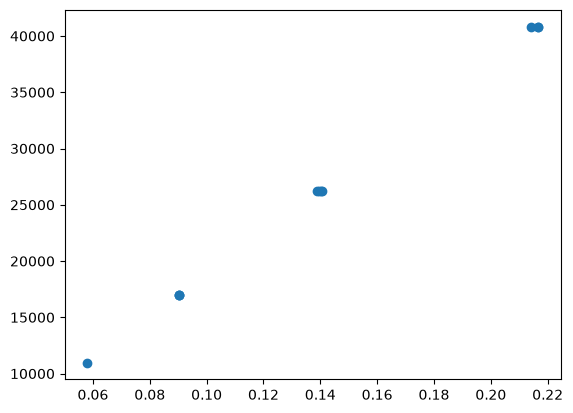

In [5]:
import matplotlib.pyplot as plt 

fig, ax = plt.subplots()
ax.scatter(df['Omega'], df['M'])

## Измерение момента инерции гироскопа

In [ ]:
# измерения для ротора и цилиндра
inertia = {
    'mass': [],     # масса груза
    'readius': [],   # радиус 
    'revolutions_N': [],    # целое число оборотов
    'time_t': [],   # время прецессии в секундах
}